In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.datasets import fetch_california_housing

In [2]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

display(df.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (20640, 9)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010



Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [4]:
X = df.drop(columns=["MedHouseVal"])

y = df["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 8)
Target shape: (20640,)


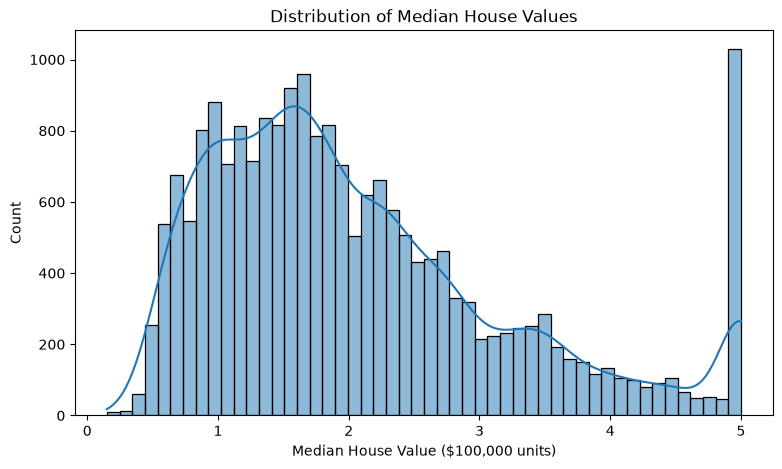

In [5]:
plt.figure(figsize=(9, 5))

sns.histplot(y, bins=50, kde=True)

plt.xlabel("Median House Value ($100,000 units)")
plt.title("Distribution of Median House Values")

plt.show()

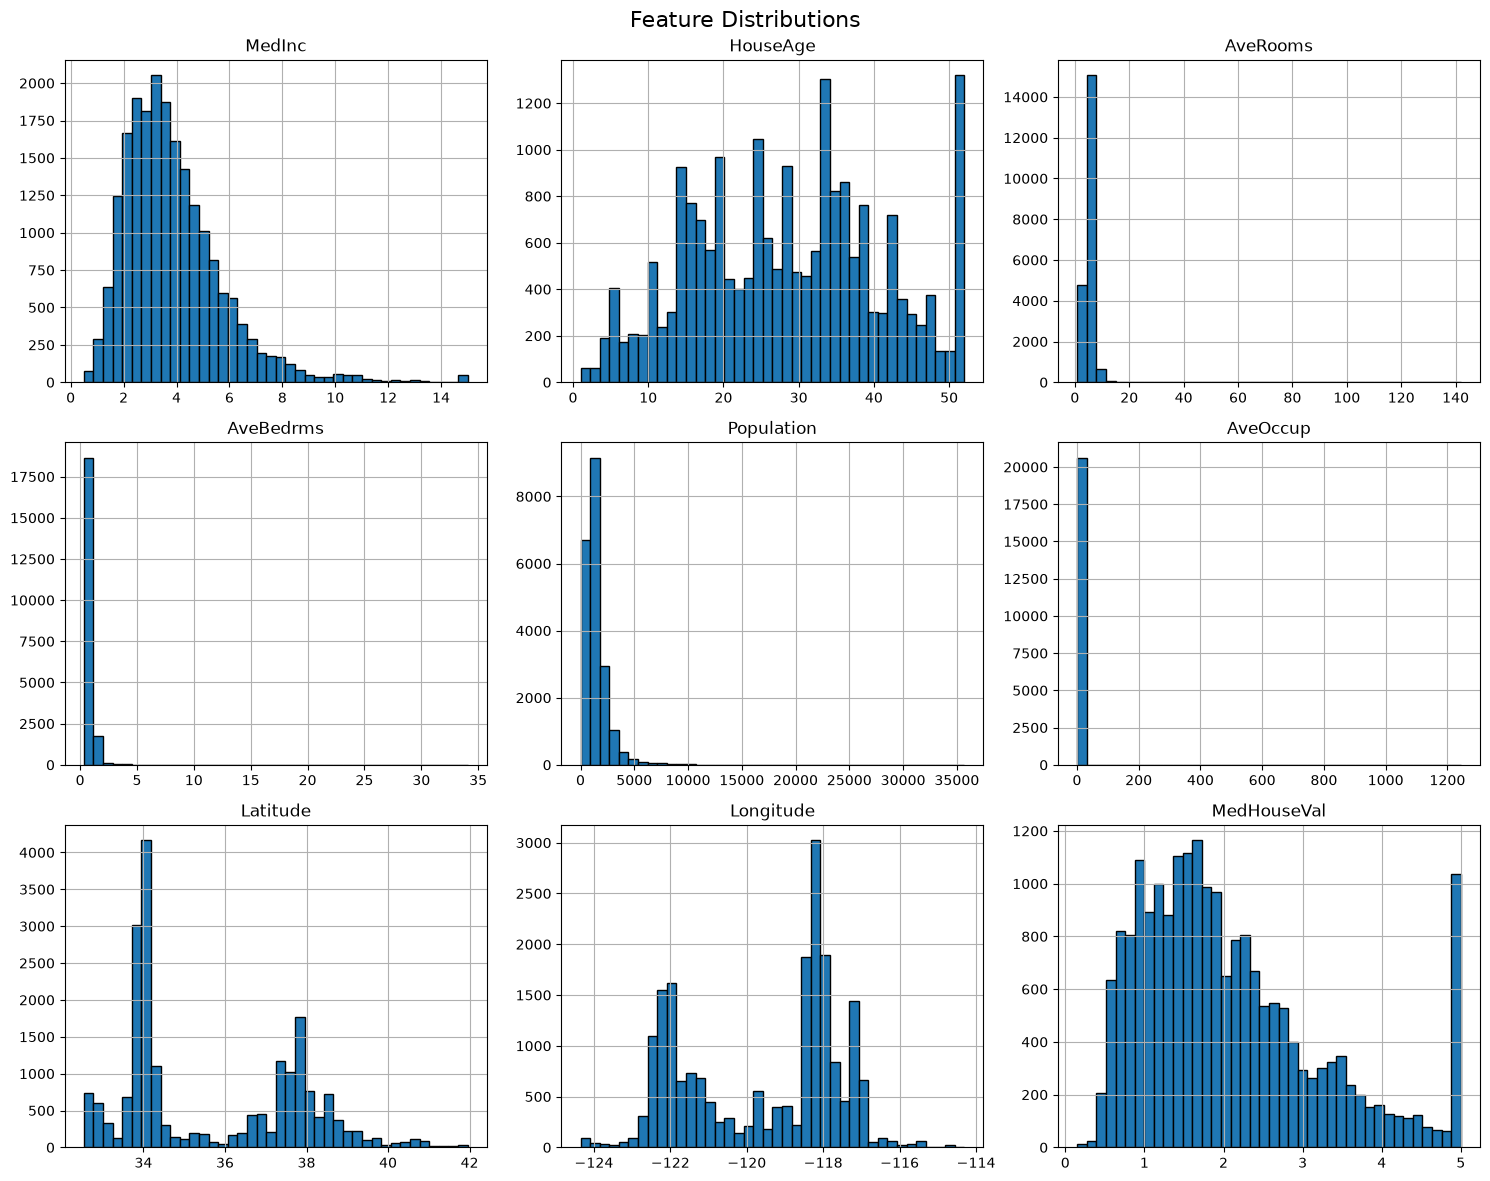

In [6]:
df.hist(
    figsize=(15, 12),
    bins=40,
    edgecolor="black"
)

plt.suptitle("Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

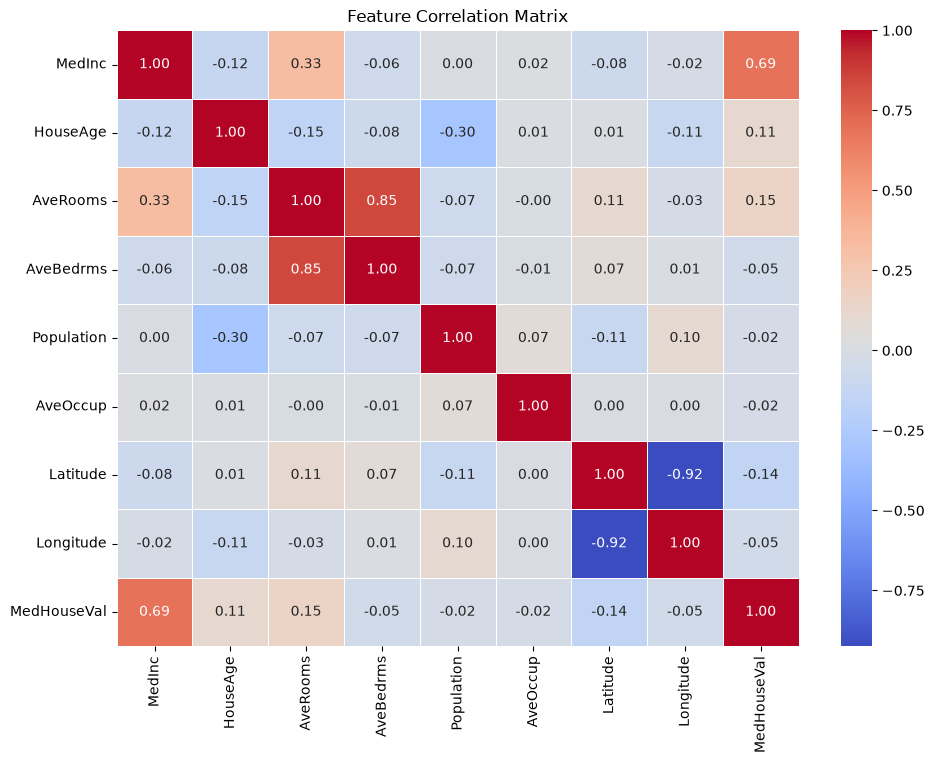

In [7]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Matrix")
plt.show()

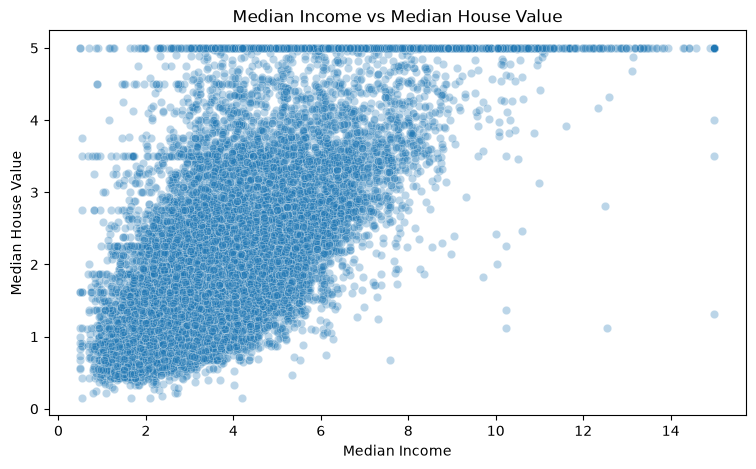

In [8]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="MedInc",
    y="MedHouseVal",
    alpha=0.3
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Median Income vs Median House Value")

plt.show()

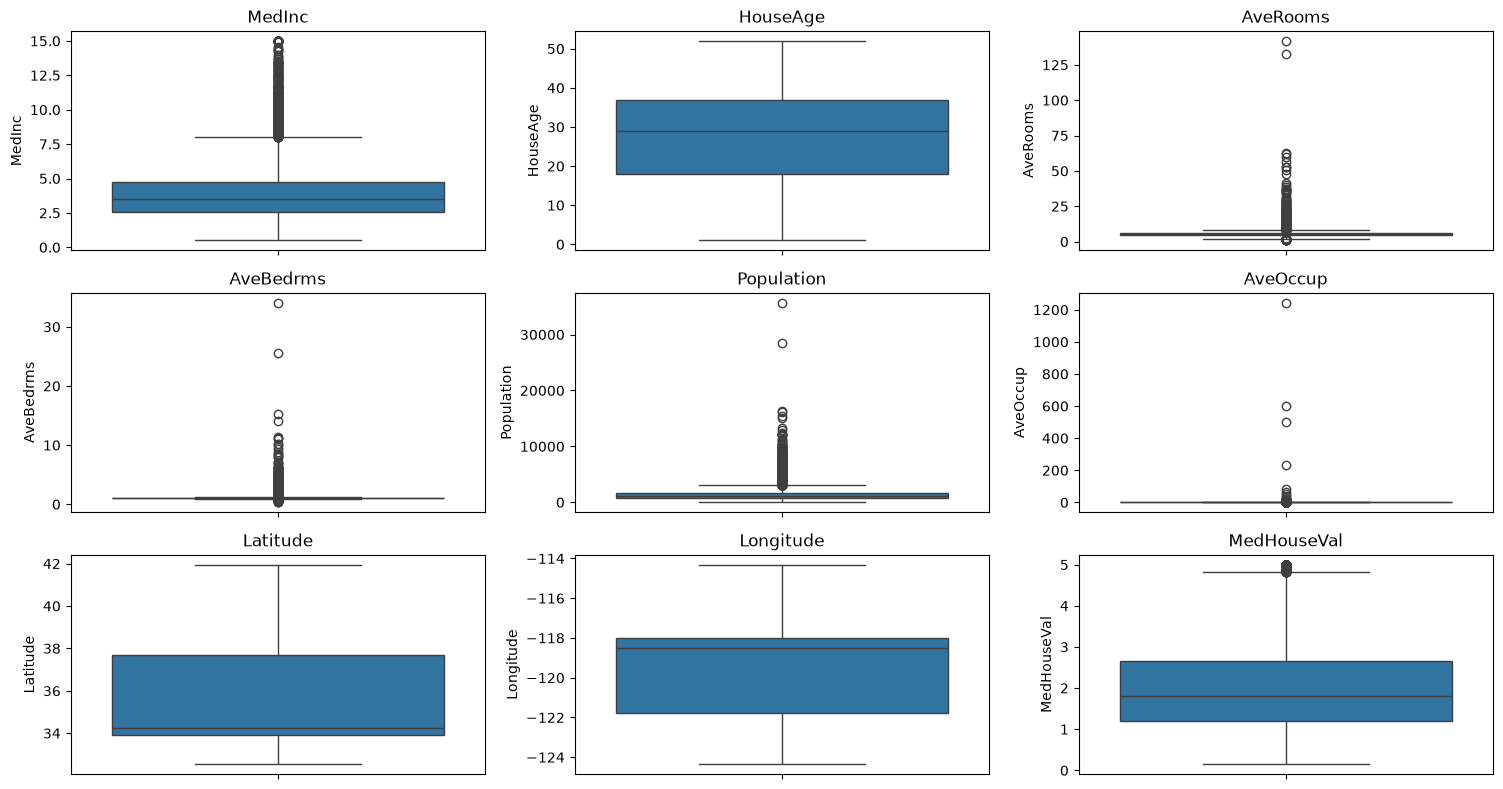

In [9]:
plt.figure(figsize=(15, 8))

for i, column in enumerate(df.columns, 1):
    plt.subplot(3, 3, i)

    sns.boxplot(y=df[column])

    plt.title(column)

plt.tight_layout()
plt.show()

In [10]:
print("Missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [11]:
correlation_with_target = (
    df.corr(numeric_only=True)["MedHouseVal"]
    .drop("MedHouseVal")
    .sort_values(ascending=False)
)

display(correlation_with_target)

MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: MedHouseVal, dtype: float64

In [12]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (16512, 8)
Testing shape: (4128, 8)


In [14]:
model_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

In [15]:
model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [16]:
y_train_predictions = model_pipeline.predict(X_train)
y_test_predictions = model_pipeline.predict(X_test)

def evaluate_regression(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

train_results = evaluate_regression(y_train, y_train_predictions)
test_results = evaluate_regression(y_test, y_test_predictions)

display(pd.DataFrame({
    "Training": train_results,
    "Testing": test_results
}))

,Training,Testing
MAE,0.528628,0.533200
MSE,0.517933,0.555892
RMSE,0.719676,0.745581
R2,0.612551,0.575788


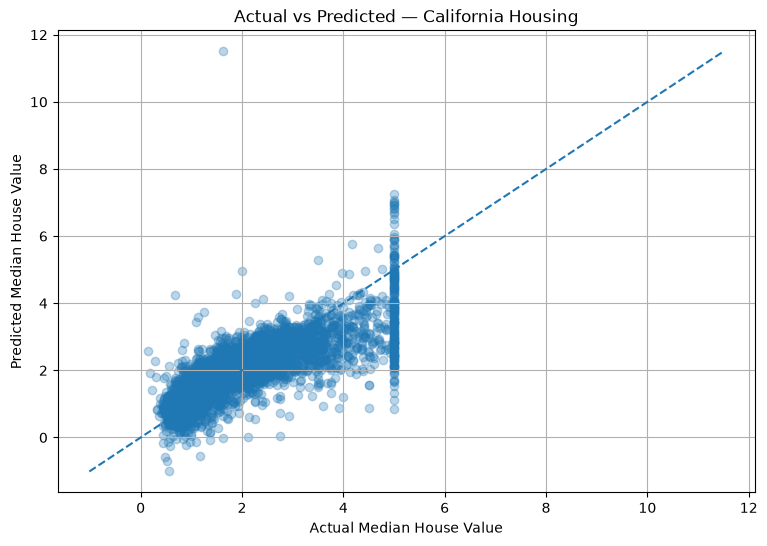

In [17]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_test_predictions,
    alpha=0.3
)

minimum = min(y_test.min(), y_test_predictions.min())
maximum = max(y_test.max(), y_test_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Actual vs Predicted — California Housing")

plt.grid(True)
plt.show()

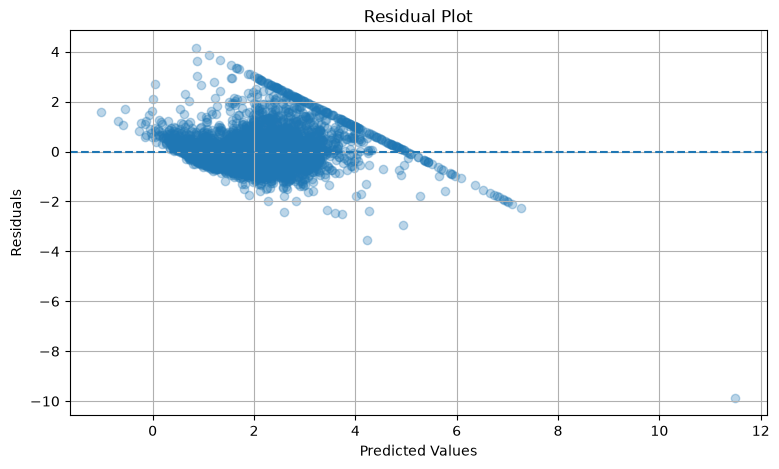

In [18]:
residuals = y_test - y_test_predictions

plt.figure(figsize=(9, 5))

plt.scatter(
    y_test_predictions,
    residuals,
    alpha=0.3
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.grid(True)
plt.show()

In [19]:
# Build a diagnostic DataFrame
diagnostics = X_test.copy()

diagnostics["Actual"] = y_test
diagnostics["Predicted"] = y_test_predictions
diagnostics["Residual"] = residuals
diagnostics["Absolute_Error"] = np.abs(residuals)

# Display the 10 largest prediction errors
largest_errors = diagnostics.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

display(largest_errors)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Actual,Predicted,Residual,Absolute_Error
1979,4.6250,34.0,132.533333,34.066667,36.0,2.400000,38.80,-120.08,1.62500,11.500331,-9.875331,9.875331
6688,0.4999,28.0,7.677419,1.870968,142.0,4.580645,34.15,-118.08,5.00001,0.851622,4.148388,4.148388
10574,1.9659,6.0,4.795455,1.159091,125.0,2.840909,33.72,-117.70,5.00001,1.115227,3.884783,3.884783
12389,3.7727,24.0,10.953586,1.848101,473.0,1.995781,33.75,-116.43,5.00001,1.319954,3.680056,3.680056
19542,1.7679,39.0,5.000000,0.888889,22.0,2.444444,37.63,-120.92,4.50000,0.867216,3.632784,3.632784
4548,7.5752,52.0,3.142857,1.000000,55.0,7.857143,34.02,-118.21,0.67500,4.236215,-3.561215,3.561215
459,1.1696,52.0,2.436000,0.944000,1349.0,5.396000,37.87,-122.25,5.00001,1.547530,3.452480,3.452480
15652,0.9000,52.0,2.237474,1.053535,3260.0,2.237474,37.80,-122.41,5.00001,1.642870,3.357140,3.357140
12069,4.2386,6.0,7.723077,1.169231,228.0,3.507692,33.83,-117.55,5.00001,1.668034,3.331976,3.331976
4630,2.3674,20.0,2.740554,1.047859,2919.0,2.450882,34.07,-118.31,5.00001,1.711156,3.288854,3.288854


In [20]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model_pipeline.named_steps["regressor"].coef_
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

display(coefficients)

,Feature,Coefficient,Absolute_Coefficient
6,Latitude,-0.896929,0.896929
7,Longitude,-0.869842,0.869842
0,MedInc,0.854383,0.854383
3,AveBedrms,0.339259,0.339259
2,AveRooms,-0.294410,0.294410
1,HouseAge,0.122546,0.122546
5,AveOccup,-0.040829,0.040829
4,Population,-0.002308,0.002308


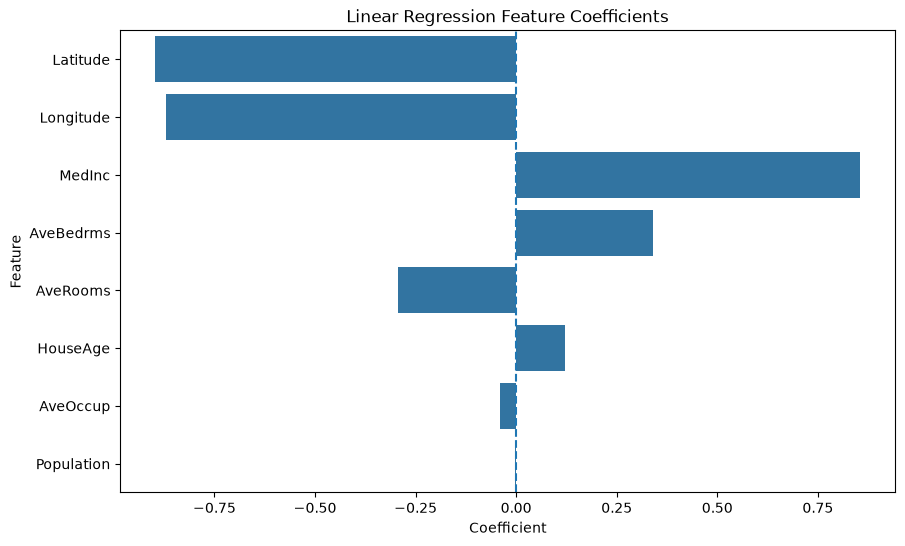

In [21]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.axvline(0, linestyle="--")
plt.show()

In [22]:
new_houses = pd.DataFrame([
    {
        "MedInc": 5.0,
        "HouseAge": 30.0,
        "AveRooms": 5.5,
        "AveBedrms": 1.0,
        "Population": 1000.0,
        "AveOccup": 3.0,
        "Latitude": 34.0,
        "Longitude": -118.0
    },
    {
        "MedInc": 3.0,
        "HouseAge": 20.0,
        "AveRooms": 4.5,
        "AveBedrms": 1.1,
        "Population": 1500.0,
        "AveOccup": 3.5,
        "Latitude": 37.0,
        "Longitude": -122.0
    }
])

In [23]:
new_predictions = model_pipeline.predict(new_houses)

inference_results = new_houses.copy()

inference_results["Predicted_Median_Value"] = new_predictions

inference_results["Predicted_Value_USD"] = (
    new_predictions * 100000
)

display(inference_results)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Predicted_Median_Value,Predicted_Value_USD
0,5.0,30.0,5.5,1.0,1000.0,3.0,34.0,-118.0,2.508690,250868.963475
1,3.0,20.0,4.5,1.1,1500.0,3.5,37.0,-122.0,2.188412,218841.190430


In [24]:
print("Predictions below zero:",
      np.sum(y_test_predictions < 0))

print("Predictions above target cap:",
      np.sum(y_test_predictions > 5))

print("Minimum prediction:",
      y_test_predictions.min())

print("Maximum prediction:",
      y_test_predictions.max())

Predictions below zero: 15
Predictions above target cap: 39
Minimum prediction: -1.0137928122566122
Maximum prediction: 11.500331025900909


## Conclusion

In this experiment, we implemented an end-to-end Linear Regression
workflow using the California Housing dataset.

### Work completed
- Loaded and inspected the real-world dataset.
- Performed exploratory data analysis.
- Investigated feature distributions, correlations and outliers.
- Split the dataset into training and testing sets.
- Built a preprocessing and regression pipeline using
  StandardScaler and LinearRegression.
- Evaluated the model using MAE, MSE, RMSE and R².
- Visualized actual versus predicted values.
- Performed residual analysis.
- Inspected learned coefficients.
- Generated predictions for new housing records.

### Evaluation results

Training R²: 0.6126  
Testing R²: 0.5758  
Testing MAE: 0.5332  
Testing RMSE: 0.7456

### Findings
- Median income has the strongest individual correlation with
  median house value.
- Geographic features contribute substantially to the
  multivariable model.
- Residual analysis indicates non-constant error variance.
- The dataset's target is capped at 5.0, limiting the
  interpretation of predictions for expensive properties.
- Linear Regression provides a useful baseline, but does not
  capture all patterns in the dataset.

### Limitations
- Linear Regression assumes an additive linear relationship
  between the input features and target.
- The target capping limits information about expensive houses.
- The model can produce predictions outside the target range.
- The dataset represents historical census data, not current
  property market prices.

### Conclusion
The experiment demonstrates the complete supervised regression
workflow, from data exploration and preprocessing to model
training, evaluation and inference.